# Food Policies in the United States: Descriptive Statistics
### DATASCI 530  · Project 2 · Whitney Barr

**Project description** 

This report describes 605 local food policies collected from the [Healthy Food Policy Project](https://healthyfoodpolicyproject.org/) database compiled in 2017 and analyzed in November 2027. For each policy, I recorded the jurisdiction, jurisdiction type, state, food system category, a short summary, and the policy URL. I use descriptive statistics, tables, and figures to show where these policies come from, which parts of the food system they address, and how often they address children and families.

## High-level findings

- **Policies are mostly local and concentrated in a few states.** About 71% are city-level, and ten states hold 57% of all policies.
- **Food access is the main focus,** followed by food production and food distribution. Processing, food prep and safety, and food recovery are each rare (about 5%).
- **Children and schools come up, but specific programs are rare.** Breastfeeding, child care, and child nutrition programs each appear in only a handful of policies.
- **Zoning and land use policies are mostly about community gardens** and where they are allowed.
- **Please note** the database only includes adopted, enforceable local laws about healthy food access, so these results describe that selection and not all food policy.
- **Please note** 173 policies (28.6%) have no food system category, so category percentages describe only what the website labeled.


# <span style="color:darkblue"> I. Data Collection and Changes Since Project 1 </span>

<font size = "3">

- Source: the Healthy Food Policy Project policy database (healthyfoodpolicyproject.org). The site collected U.S. food policies in 2017.
- The database only includes written laws and policies adopted by municipal governments (cities, counties, towns and villages), such as ordinances, resolutions and codified laws. It does not include state, federal or Tribal laws, or policies from school boards, park boards and other special local governments. The "state" column only tells me where a jurisdiction is.
- It also leaves out policies that are only aspirational or advisory, such as plans, task forces and statements of commitment. A policy is included when it has specific, enforceable requirements about healthy food access.
- I collected the data on **21 October 2026** with Selenium, which opens each policy page in Chrome. There are 605 policies, with one row per policy.
- Variables: jurisdiction name, jurisdiction type, state, food system category, summary text and policy URL.
- The data are saved in `policy_data_selenium.csv`. I read this file in the next cell.


# <span style="color:darkblue"> Import Packages and Load the Data </span>

<font size = "3">

Pandas organizes the data into tables, matplotlib makes the figures, and `WordCloud` makes the word clouds.


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from wordcloud import WordCloud, STOPWORDS

In [3]:
food_policy_actions = pd.read_csv("policy_data_selenium.csv")
num_policies = len(food_policy_actions)

# Lowercase copy of the summary so searches ignore capital letters
food_policy_actions["summary_lower"] = food_policy_actions["summary"].str.lower()

# Format a table for reporting: caption, alignment, optional percent bars
def make_pretty(table, caption, number_format, left_cols, center_cols, bar_col = None):
    styled = (table.style.format(number_format).hide(axis = "index")
              .set_caption(caption)
              .set_properties(subset = left_cols, **{"text-align": "left", "white-space": "normal", "vertical-align": "top"})
              .set_properties(subset = center_cols, **{"text-align": "center"})
              .set_table_styles([{"selector": "th",
                                  "props": [("text-align", "center"), ("font-weight", "bold"),
                                            ("background-color", "white"), ("border-bottom", "2px solid black")]},
                                 {"selector": "caption",
                                  "props": [("caption-side", "top"), ("text-align", "left"),
                                            ("font-weight", "bold"), ("font-size", "1.1em")]}]))
    if bar_col is not None:
        styled = styled.bar(subset = [bar_col], color = "#5fa8d3", vmin = 0, vmax = 100)
    return styled


# <span style="color:darkblue"> II. Overview of the Data </span>

<font size = "3">

**Table 1** includes the number of observations, mean, variance, median and maximum for the number of policies in each state, the number of policies in each jurisdiction and the number of food system categories each policy has. **Table 2** displays missing values.


In [4]:
policies_per_state = food_policy_actions["state"].value_counts()
policies_per_jurisdiction = food_policy_actions["jurisdiction"].value_counts()

# One True/False column per food system category (used here and in later tables)
# "== True" turns the blank categories into False
list_old = ["Grow", "Process", "Distribute", "Get", "Make", "Surplus"]
list_new = ["Food Production", "Food Processing", "Food Distribution", "Food Access",
            "Food Prep and Safety", "Food Recovery and Waste Management"]
list_flags = []
for i in range(len(list_old)):
    flag = "has_" + list_old[i]
    food_policy_actions[flag] = food_policy_actions["policy_category"].str.contains(list_old[i]) == True
    list_flags.append(flag)

with_category = food_policy_actions[food_policy_actions["policy_category"].notnull()]
categories_per_policy = with_category[list_flags].sum(axis = 1)

list_names = ["Policies per state", "Policies per jurisdiction", "Food system categories per policy"]
list_series = [policies_per_state, policies_per_jurisdiction, categories_per_policy]

table_overview = pd.DataFrame({
    "Variable": list_names,
    "Observations": [len(s) for s in list_series],
    "Mean": [s.mean() for s in list_series],
    "Variance": [s.std() ** 2 for s in list_series],
    "Median": [s.median() for s in list_series],
    "Maximum": [s.max() for s in list_series]})

make_pretty(table_overview,
            "Table 1. Summary statistics (" + str(num_policies) + " policies; categories per policy use the policies that have a category)",
            {"Mean": "{:.1f}", "Variance": "{:.1f}", "Median": "{:.0f}", "Maximum": "{:.0f}"},
            ["Variable"], ["Observations", "Mean", "Variance", "Median", "Maximum"])


Variable,Observations,Mean,Variance,Median,Maximum
Policies per state,51,11.9,233.5,7,92
Policies per jurisdiction,354,1.7,3.5,1,21
Food system categories per policy,432,1.8,0.5,2,6


There are 605 policies from 354 jurisdictions in 51 states. Food system policies are not spread evenly across states. The average state has ~12 (11.9) food policies, but the median is only 7 and the variance is large (233.5). The large variance shows how varied food policy is across US cities and states. California has 92 policies, which helps pull up the mean. Most jurisdictions show up only once meaning that they have one food systems-related policy. The mean is 1.7 policies per jurisdiction and the median is 1, but San Francisco alone has 21. Among the 432 policies that have a category, the average policy has 1.8 categories and the median is 2.


In [5]:
list_columns = ["jurisdiction", "jurisdiction_type", "state", "policy_category", "summary", "url"]

table_missing = pd.DataFrame({
    "Variable": ["Jurisdiction", "Jurisdiction Type", "State", "Food System Category", "Summary", "URL"],
    "Observations": list(food_policy_actions[list_columns].notnull().sum())})
table_missing["Missing"] = num_policies - table_missing["Observations"]
table_missing["Percent Missing"] = table_missing["Missing"] / num_policies * 100

make_pretty(table_missing, "Table 2. Observations and missing values by variable (N = " + str(num_policies) + ")",
            {"Percent Missing": "{:.1f}%"},
            ["Variable"], ["Observations", "Missing", "Percent Missing"], "Percent Missing")


Variable,Observations,Missing,Percent Missing
Jurisdiction,605,0,0.0%
Jurisdiction Type,604,1,0.2%
State,605,0,0.0%
Food System Category,432,173,28.6%
Summary,604,1,0.2%
URL,605,0,0.0%


173 policies (28.6%) have no food system category. Many of these look like temporary emergency policies. 63 of the 173 mention COVID-19 or an emergency. Jurisdiction type and summary are each missing for one policy (0.2%). Every other column is complete.


# <span style="color:darkblue"> III. Food System Categories </span>

<font size = "3">

- The website labels each policy with action words: Grow, Process, Distribute, Get, Make and Surplus.
- I rename them to food system terms so they are easier to read. This only changes the names in the tables. It does not change the data.
- A policy can have more than one category, so the percentages add up to more than 100%.
- The percentages use all 605 policies.


In [6]:
counts = []
for flag in list_flags:
    counts.append(food_policy_actions[flag].sum())

table_category = pd.DataFrame({"Category": list_new, "Number of Policies": counts})
table_category["Percent of All Policies"] = table_category["Number of Policies"] / num_policies * 100
table_category = table_category.sort_values("Number of Policies", ascending = False)

make_pretty(table_category,
            "Table 3. Policies by food system category (N = " + str(num_policies) + "; a policy can have several categories)",
            {"Percent of All Policies": "{:.1f}%"},
            ["Category"], ["Number of Policies", "Percent of All Policies"], "Percent of All Policies")


Category,Number of Policies,Percent of All Policies
Food Access,306,50.6%
Food Production,202,33.4%
Food Distribution,169,27.9%
Food Prep and Safety,31,5.1%
Food Recovery and Waste Management,30,5.0%
Food Processing,27,4.5%


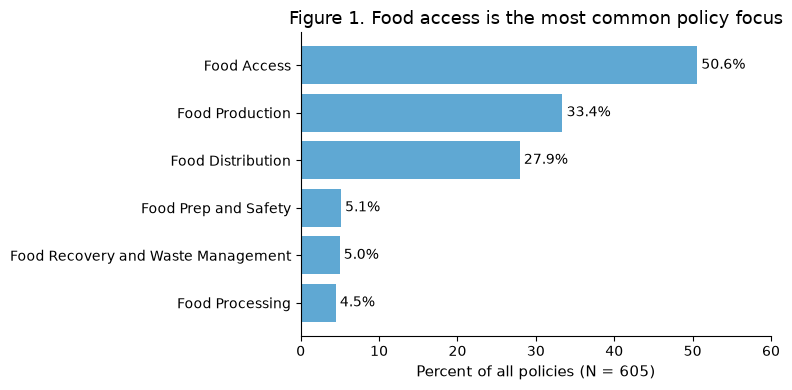

In [7]:
fig, ax = plt.subplots(figsize = (8, 4))
bars = ax.barh(table_category["Category"], table_category["Percent of All Policies"], color = "#5fa8d3")
ax.bar_label(bars, fmt = "%.1f%%", padding = 3, fontsize = 10)
ax.invert_yaxis()
ax.set_xlim(0, 60)
ax.set_xlabel("Percent of all policies (N = " + str(num_policies) + ")", fontsize = 11)
ax.set_title("Figure 1. Food access is the most common policy focus", fontsize = 13)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()


Half of the policies (50.6%) address food access, one third (33.4%) address food production and 27.9% address food distribution. Food prep and safety (5.1%), food recovery and waste management (5.0%) and food processing (4.5%) are much less common. Most policies are about getting food to people or growing food locally. Very few are about processing.


# <span style="color:darkblue"> IV. Policies Related to Children and Families </span>

<font size = "3">

- I search each policy summary for the terms in a codebook of children and family topics, such as "infant", "school lunch" and "WIC".
- A policy counts for a topic if its summary has any of that topic's terms.
- This is simple text matching, so a few policies may match a word that has a different meaning. For example, "lead" can mean the metal or the verb.


In [8]:
CODEBOOK = {
    "maternal_pregnancy": [
        "mother", "mothers", "maternal", "maternity",
        "pregnant", "pregnancy", "prenatal", "perinatal", "postpartum",
        "birth", "doula", "midwife", "obstetric",
        "parental leave", "family leave",
    ],
    "breastfeeding_lactation": [
        "breast milk", "breastfeed", "breastfeeding", "breast-feed",
        "lactation", "nursing mother",
    ],
    "infant_early_childhood": [
        "infant", "infants", "newborn", "baby", "babies", "toddler",
        "infant formula", "early childhood", "early learning",
        "pre-k", "pre-kindergarten", "preschool",
        "head start", "early head start",
    ],
    "child_care": [
        "child care", "childcare", "day care", "daycare",
        "child care learning center", "family child care learning home",
        "after-school", "afterschool", "after school",
    ],
    "children_youth": [
        "child", "children", "childhood", "kid", "kids",
        "youth", "minor", "minors", "adolescent",
        "teen", "teens", "teenager", "juvenile",
        "under 18", "under the age of",
    ],
    "schools_education": [
        "school", "schools", "student", "students", "k-12",
        "school district", "board of education",
        "school zone", "safe routes to school",
    ],
    "child_nutrition_programs": [
        "school lunch", "school breakfast", "school meal",
        "summer meal", "nslp", "sbp", "cacfp", "sfsp",
        "seamless summer", "summer ebt", "sun bucks",
        "free and reduced", "community eligibility",
        "farm to school", "smart snacks", "competitive food",
    ],
    "food_benefits": [
        "snap", "wic", "ebt", "tanf",
        "supplemental nutrition assistance",
        "women, infants, and children",
    ],
    "health_coverage": [
        "medicaid", "peachcare",
    ],
    "family_household": [
        "family", "families", "parent", "parents", "parenting",
        "guardian", "caregiver", "dependent",
        "household with children", "foster care", "custody",
        "child tax credit",
    ],
    "georgia_agencies": [
        "decal", "caps", "quality rated", "georgia pre-k",
        "dfcs", "gadoe", "department of public health",
    ],
    "play_recreation": [
        "playground", "play area", "recreation center",
        "tot lot", "splash pad",
    ],
    "food_environment_marketing": [
        "candy", "sugar-sweetened beverage", "sugary drink",
        "vending", "marketing to children", "lead",
    ],
}

# Readable names for tables and figures
LABELS = {
    "maternal_pregnancy": "Maternal and Pregnancy",
    "breastfeeding_lactation": "Breastfeeding and Lactation",
    "infant_early_childhood": "Infants and Early Childhood",
    "child_care": "Child Care",
    "children_youth": "Children and Youth",
    "schools_education": "Schools and Education",
    "child_nutrition_programs": "Child Nutrition Programs",
    "food_benefits": "Food Benefits (SNAP, WIC, EBT)",
    "health_coverage": "Health Coverage (Medicaid)",
    "family_household": "Family and Household",
    "georgia_agencies": "Georgia Agencies",
    "play_recreation": "Play and Recreation",
    "food_environment_marketing": "Food Environment and Marketing",
}

In [9]:
# True/False column for each topic: does the summary contain any of its terms?
for category in CODEBOOK:
    found = False
    for term in CODEBOOK[category]:
        found = found | (food_policy_actions["summary_lower"].str.contains(term) == True)
    food_policy_actions[category] = found

counts = []
for category in CODEBOOK:
    counts.append(food_policy_actions[category].sum())

table_codebook = pd.DataFrame({"Topic": list(LABELS.values()), "Number of Policies": counts})
table_codebook["Percent of All Policies"] = table_codebook["Number of Policies"] / num_policies * 100
table_codebook = table_codebook.sort_values("Number of Policies", ascending = False)

make_pretty(table_codebook,
            "Table 4. Policies mentioning children and family topics (N = " + str(num_policies) + "; a policy can mention several topics)",
            {"Percent of All Policies": "{:.1f}%"},
            ["Topic"], ["Number of Policies", "Percent of All Policies"], "Percent of All Policies")


Topic,Number of Policies,Percent of All Policies
Children and Youth,66,10.9%
Schools and Education,40,6.6%
Food Environment and Marketing,25,4.1%
Family and Household,23,3.8%
"Food Benefits (SNAP, WIC, EBT)",18,3.0%
Breastfeeding and Lactation,12,2.0%
Infants and Early Childhood,11,1.8%
Maternal and Pregnancy,10,1.7%
Child Care,7,1.2%
Child Nutrition Programs,4,0.7%


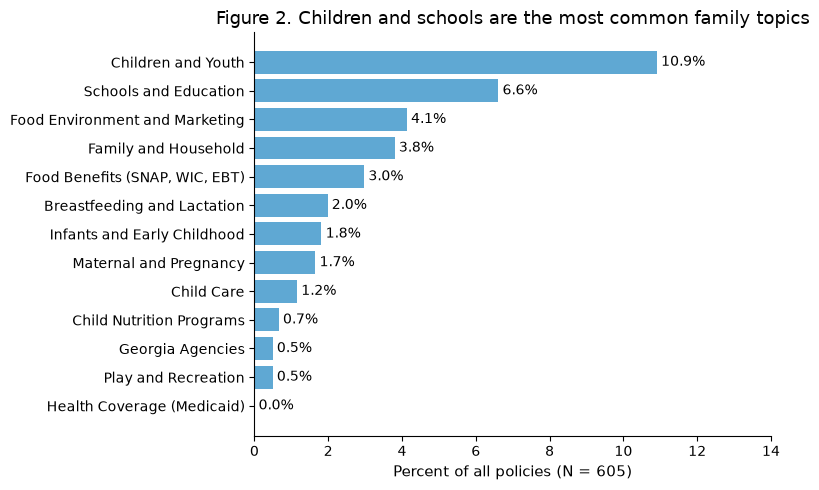

In [10]:
fig, ax = plt.subplots(figsize = (8, 5))
bars = ax.barh(table_codebook["Topic"], table_codebook["Percent of All Policies"], color = "#5fa8d3")
ax.bar_label(bars, fmt = "%.1f%%", padding = 3, fontsize = 10)
ax.invert_yaxis()
ax.set_xlim(0, 14)
ax.set_xlabel("Percent of all policies (N = " + str(num_policies) + ")", fontsize = 11)
ax.set_title("Figure 2. Children and schools are the most common family topics", fontsize = 13)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()


Children and youth is the most common topic (66 policies, 10.9%). Schools and education is next (40 policies, 6.6%), followed by food environment and marketing (25), family and household (23) and food benefits such as SNAP and WIC (18). The more specific topics are rare: breastfeeding (12 policies), infants and early childhood (11), maternal and pregnancy (10), child care (7) and child nutrition programs (4). No policy mentions Medicaid or PeachCare. Topics with only a few policies should be read with caution.


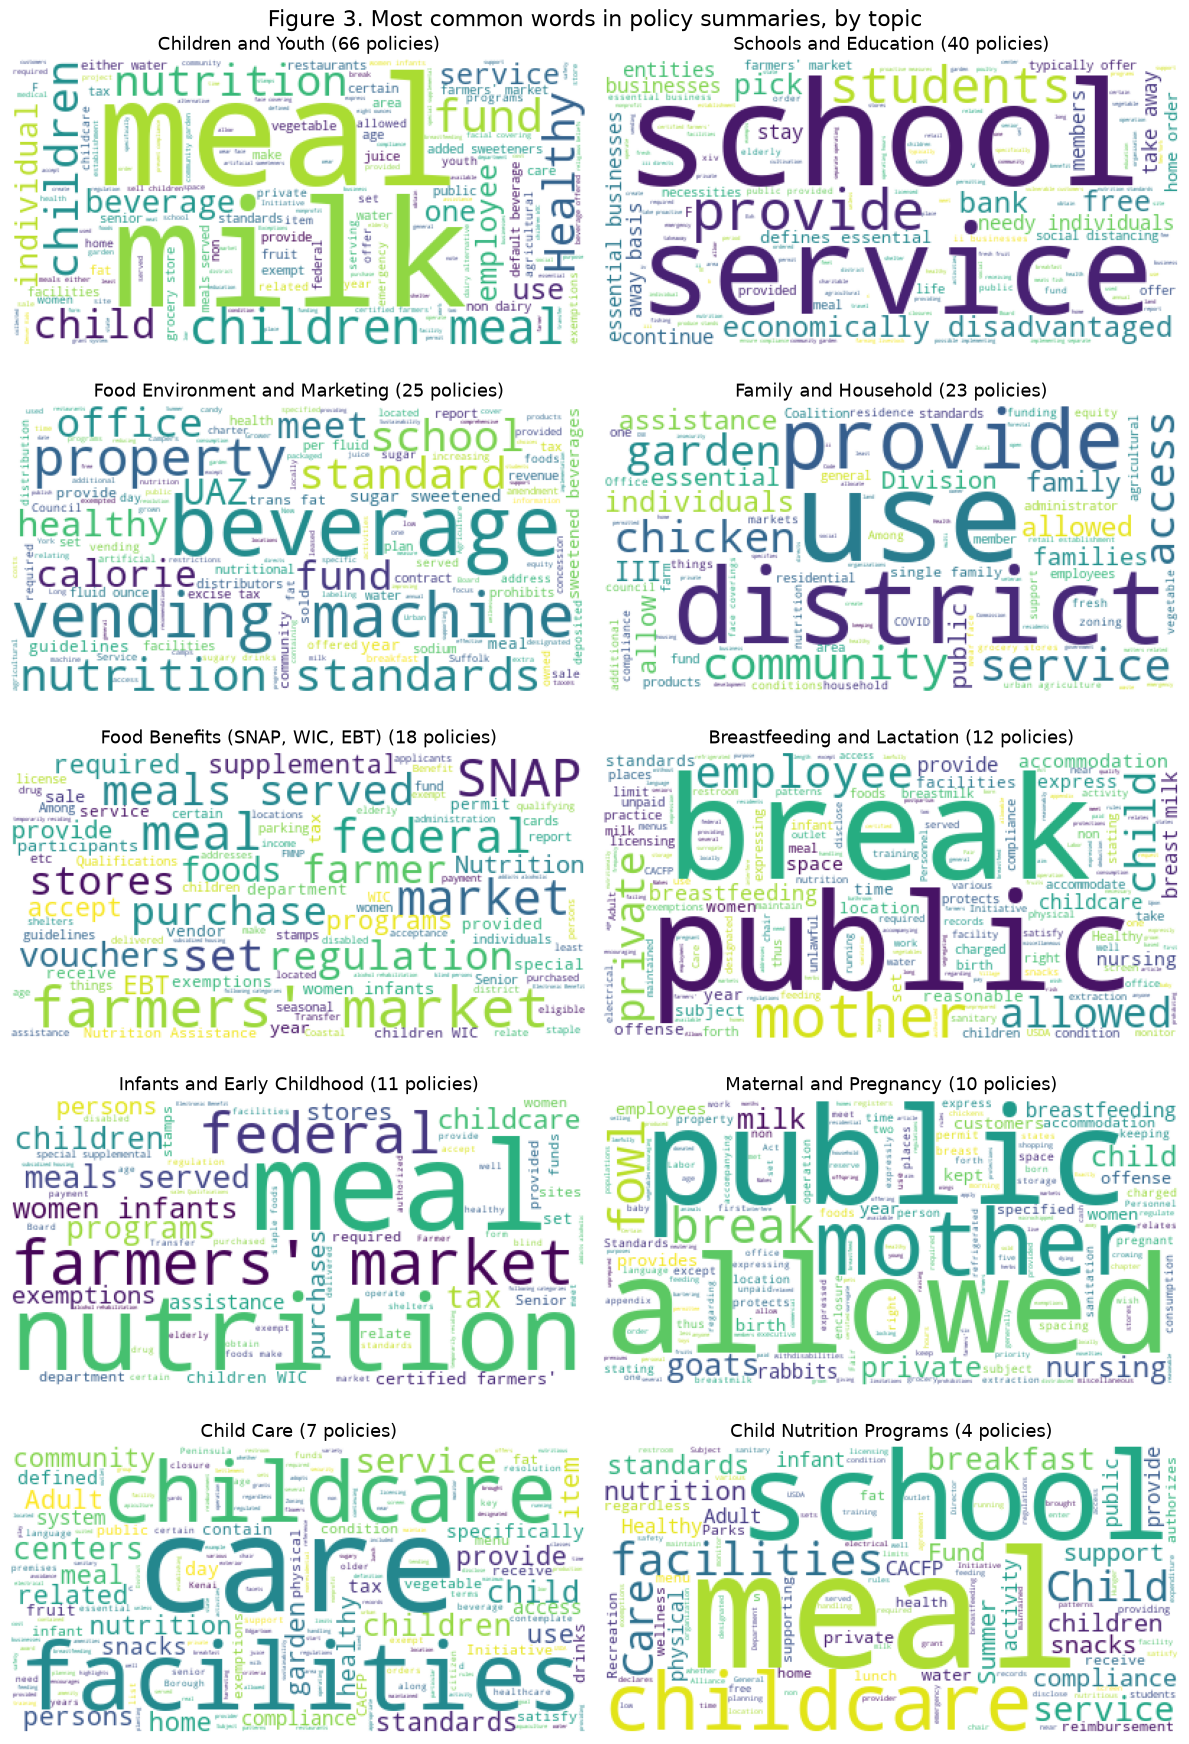

In [11]:
# Word clouds for the ten most common topics
stop_words = list(STOPWORDS) + ["food", "policy", "section", "city", "county", "will", "may", "shall", "law",
                                "ordinance", "provision", "provisions", "requires", "require", "requirement",
                                "requirements", "also", "including", "include", "includes", "must", "within",
                                "establishes", "program", "e", "g"]

list_keys = list(CODEBOOK.keys())
list_labels = list(LABELS.values())
list_top10 = list(table_codebook["Topic"].head(10))

fig, ax = plt.subplots(5, 2, figsize = (12, 18))

for i in range(len(list_top10)):
    topic = list_top10[i]
    key = list_keys[list_labels.index(topic)]
    subset = food_policy_actions[food_policy_actions[key]]
    text = " ".join(subset["summary"])
    word_cloud = WordCloud(background_color = "white", stopwords = stop_words).generate(text)

    ax[i // 2, i % 2].imshow(word_cloud)
    ax[i // 2, i % 2].set_title(topic + " (" + str(len(subset)) + " policies)", fontsize = 13)
    ax[i // 2, i % 2].axis("off")

fig.suptitle("Figure 3. Most common words in policy summaries, by topic", fontsize = 16)
plt.tight_layout()
plt.show()


Bigger words show up more often in the summaries. The children and youth and schools clouds have words like "meal", "school", "milk" and "students", so many of these policies are about school meals and milk. The breastfeeding cloud has "break", "public", "mother", "employee" and "private", which fits rules about nursing in public and at work. The food environment cloud has "beverage", "vending" and "nutrition". The maternal and pregnancy cloud has livestock words like "fowl" and "goats", which means the keyword search picked up a few policies it should not have.


# <span style="color:darkblue"> V. Where the Policies Come From </span>

<font size = "3">

I count the policies by jurisdiction type and then look at the ten states with the most policies. 27 policies are labeled both city and county, so I count them in both groups.


In [12]:
list_types = ["City", "County", "Town/Township", "Other."]
list_labels = ["City", "County", "Town/Township", "Other"]

counts = []
for t in list_types:
    counts.append((food_policy_actions["jurisdiction_type"].str.contains(t) == True).sum())

table_type = pd.DataFrame({"Jurisdiction Type": list_labels, "Number of Policies": counts})
table_type["Percent of All Policies"] = table_type["Number of Policies"] / num_policies * 100
table_type = table_type.sort_values("Number of Policies", ascending = False)

make_pretty(table_type,
            "Table 5. Policies by jurisdiction type (N = " + str(num_policies) + "; 27 policies are labeled both city and county; Other includes boroughs, parishes, and metro governments)",
            {"Percent of All Policies": "{:.1f}%"},
            ["Jurisdiction Type"], ["Number of Policies", "Percent of All Policies"], "Percent of All Policies")


Jurisdiction Type,Number of Policies,Percent of All Policies
City,431,71.2%
County,150,24.8%
Town/Township,25,4.1%
Other,25,4.1%


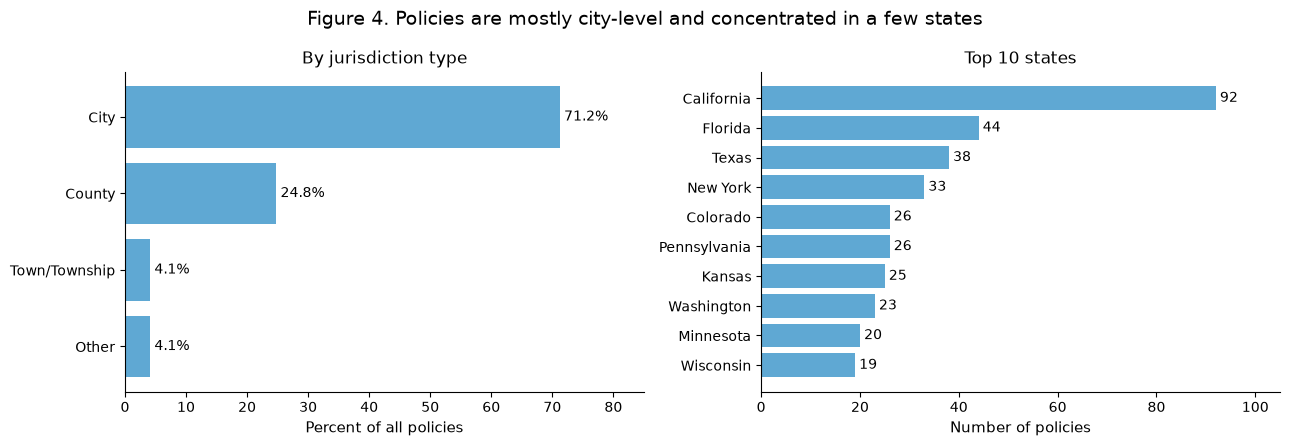

In [13]:
top_states = food_policy_actions["state"].value_counts().head(10)

fig, ax = plt.subplots(1, 2, figsize = (13, 4.5))

bars = ax[0].barh(table_type["Jurisdiction Type"], table_type["Percent of All Policies"], color = "#5fa8d3")
ax[0].bar_label(bars, fmt = "%.1f%%", padding = 3, fontsize = 10)
ax[0].invert_yaxis()
ax[0].set_xlim(0, 85)
ax[0].set_xlabel("Percent of all policies", fontsize = 11)
ax[0].set_title("By jurisdiction type", fontsize = 12)

bars = ax[1].barh(list(top_states.index), list(top_states), color = "#5fa8d3")
ax[1].bar_label(bars, padding = 3, fontsize = 10)
ax[1].invert_yaxis()
ax[1].set_xlim(0, 105)
ax[1].set_xlabel("Number of policies", fontsize = 11)
ax[1].set_title("Top 10 states", fontsize = 12)

for i in range(2):
    ax[i].spines[["top", "right"]].set_visible(False)

fig.suptitle("Figure 4. Policies are mostly city-level and concentrated in a few states", fontsize = 14)
plt.tight_layout()
plt.show()


 431 policies (71.2%) are city-level and 150 (24.8%) are county-level. Towns/townships and other types are about 4% each. California has the most policies (92, 15.2%), then Florida (44) and Texas (38). The top ten states have 346 policies in total and make up 57.2% of the database. This may be because the database covers some states better than others, and not only because those states are more active.


# <span style="color:darkblue"> VI. Categories by Jurisdiction Type </span>

<font size = "3">

- Table 6 compares the food system categories for cities, counties and all other types.
- I calculate the percentages within each jurisdiction type, using only the policies that have a category. They cannot be compared directly with Table 3.


In [ ]:
data_cat = food_policy_actions[food_policy_actions["policy_category"].notnull()].copy()

# Group jurisdiction types into City, County, and everything else
data_cat["type_group"] = "Other or combined"
data_cat.loc[data_cat["jurisdiction_type"] == "City", "type_group"] = "City"
data_cat.loc[data_cat["jurisdiction_type"] == "County", "type_group"] = "County"

list_groups = ["City", "County", "Other or combined"]

table_type_category = pd.DataFrame({"Jurisdiction Type": list_groups})
table_type_category["Policies with a Category"] = [(data_cat["type_group"] == g).sum() for g in list_groups]

for i in range(len(list_old)):
    values = []
    for g in list_groups:
        group = data_cat[data_cat["type_group"] == g]
        values.append(group[list_flags[i]].mean() * 100)
    table_type_category[list_new[i] + " (%)"] = values

#The categories are stored in `list_new` in the website's original order (Grow, Process, Distribute, Get, Make, Surplus). I want Table 6 to read from the most common category to the least common, as in Table 3. The numbers `[3, 0, 2, 1, 4, 5]` are positions in `list_new`, so the loop builds the column names in this order: Food Access, Food Production, Food Distribution, Food Processing, Food Prep and Safety, then Food Recovery and Waste Management. The last line keeps the jurisdiction type and the number of policies first, then adds the category columns in that order. This only changes how the table is displayed, not the numbers.
list_cols = []
for i in [3, 0, 2, 1, 4, 5]:
    list_cols.append(list_new[i] + " (%)")
table_type_category = table_type_category[["Jurisdiction Type", "Policies with a Category"] + list_cols]

make_pretty(table_type_category,
            "Table 6. Food system categories by jurisdiction type (" + str(len(data_cat)) + " policies with a category; a policy can have several categories)",
            {col: "{:.1f}" for col in list_cols},
            ["Jurisdiction Type"], list(table_type_category.columns[1:]))


Jurisdiction Type,Policies with a Category,Food Access (%),Food Production (%),Food Distribution (%),Food Processing (%),Food Prep and Safety (%),Food Recovery and Waste Management (%)
City,295,70.2,50.2,36.3,5.4,7.5,6.8
County,69,76.8,33.3,43.5,8.7,5.8,8.7
Other or combined,68,67.6,45.6,47.1,7.4,7.4,5.9


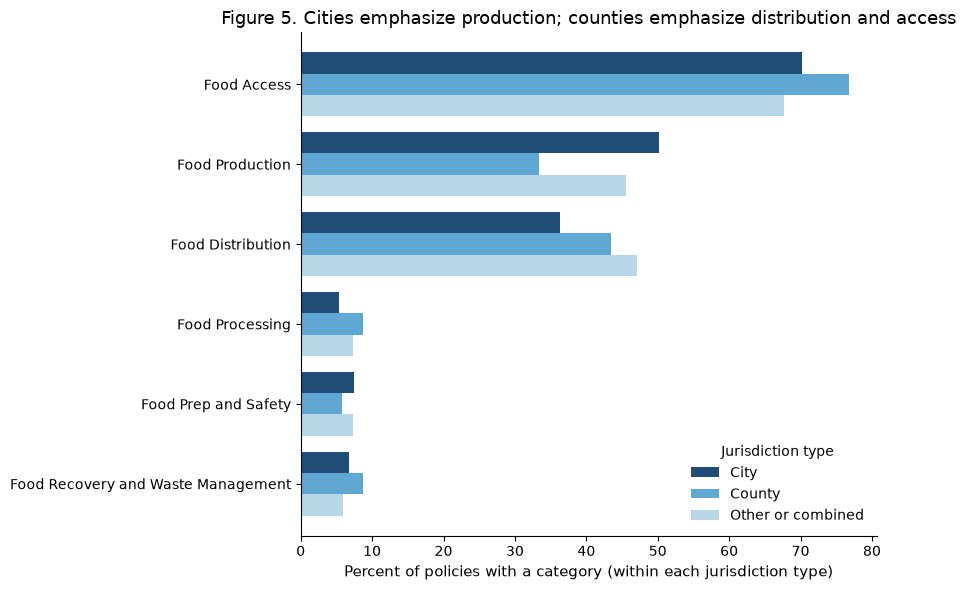

In [15]:
table_plot5 = table_type_category.set_index("Jurisdiction Type").drop(columns = "Policies with a Category")
table_plot5 = table_plot5.rename(columns = {col: col.replace(" (%)", "") for col in table_plot5.columns})

ax = table_plot5.T.plot(kind = "barh", figsize = (9, 6), color = ["#1f4e79", "#5fa8d3", "#b7d7e8"], width = 0.8)
ax.invert_yaxis()
ax.set_xlabel("Percent of policies with a category (within each jurisdiction type)", fontsize = 11)
ax.set_ylabel("")
ax.set_title("Figure 5. Cities emphasize production; counties emphasize distribution and access", fontsize = 13)
ax.legend(title = "Jurisdiction type", frameon = False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()


Food access is the most common focus for every type of government (68% to 77% of policies). After that the priorities differ. Cities focus more on food production (50.2% of city policies compared with 33.3% for counties). Counties and the other types, respectively, focus more on food distribution (43.5% and 47.1% compared with 36.3% for cities). Counties also have the highest shares for food processing (8.7%) and food recovery and waste management (8.7%). The county and other groups are small (69 and 68 policies), so I read these as patterns and not exact numbers.


# <span style="color:darkblue"> VII. What the Policies Talk About </span>

<font size = "3">

- The website categories are broad, so I also search the summaries for common themes, such as gardens, taxes and livestock and create dictionaries for the themes.
- This works similarly to the children and family codebook that I created based what I have seen within municipal code throughout my career and common terms within literature. A policy counts for a theme if its summary has any of the theme's terms, and a policy can have more than one theme.


In [ ]:
THEMES = {
    "Urban agriculture and gardens": ["urban agricultur", "community garden", "garden"],
    "Taxes, incentives, grants, and funding": ["tax", "incentive", "grant", "fund"],
    "Livestock (chickens, bees, goats)": ["chicken", "livestock", "bees", "hens", "goat"],
    "Zoning and land use": ["zoning", "land use"],
    "COVID-19 and emergencies": ["covid", "pandemic", "emergency"],
    "Nutrition standards": ["nutrition standard", "healthy"],
    "Farmers markets": ["farmers market", "farmers' market", "farmer's market"],
    "Food banks and pantries": ["food bank", "pantry", "pantries"],
    "Donation and liability": ["donat", "liability", "gleaning"],
    "Food waste and composting": ["compost", "waste", "surplus"],
    "Food trucks and vendors": ["food truck", "vendor", "mobile food"],
}
#For each theme, I check each policy summary for any of the theme's search terms. `str.contains(term)` gives True or False for each summary, and `|` means "or", so `found` is True when a summary has at least one of the terms. I start with `found = False` so the first term has something to combine with. `== True` turns summaries that are missing (blank) into False. Adding up the True values with `found.sum()` gives the number of policies for that theme. A policy is only counted once per theme, even if it matches several terms, but it can count for more than one theme.
counts = []
for theme in THEMES:
    found = False
    for term in THEMES[theme]:
        found = found | (food_policy_actions["summary_lower"].str.contains(term) == True)
    counts.append(found.sum())

table_themes = pd.DataFrame({"Theme": list(THEMES.keys()), "Number of Policies": counts})
table_themes["Percent of All Policies"] = table_themes["Number of Policies"] / num_policies * 100
table_themes = table_themes.sort_values("Number of Policies", ascending = False)

make_pretty(table_themes,
            "Table 7. Policy themes in the summaries (N = " + str(num_policies) + "; a policy can have several themes)",
            {"Percent of All Policies": "{:.1f}%"},
            ["Theme"], ["Number of Policies", "Percent of All Policies"], "Percent of All Policies")


Theme,Number of Policies,Percent of All Policies
Urban agriculture and gardens,152,25.1%
"Taxes, incentives, grants, and funding",103,17.0%
"Livestock (chickens, bees, goats)",95,15.7%
COVID-19 and emergencies,74,12.2%
Nutrition standards,62,10.2%
Food banks and pantries,51,8.4%
Zoning and land use,50,8.3%
Farmers markets,50,8.3%
Donation and liability,41,6.8%
Food waste and composting,38,6.3%


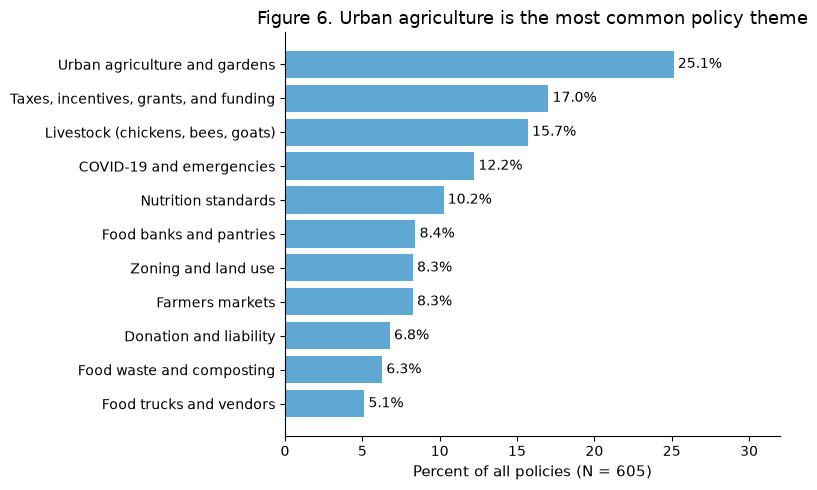

In [17]:
fig, ax = plt.subplots(figsize = (8, 5))
bars = ax.barh(table_themes["Theme"], table_themes["Percent of All Policies"], color = "#5fa8d3")
ax.bar_label(bars, fmt = "%.1f%%", padding = 3, fontsize = 10)
ax.invert_yaxis()
ax.set_xlim(0, 32)
ax.set_xlabel("Percent of all policies (N = " + str(num_policies) + ")", fontsize = 11)
ax.set_title("Figure 6. Urban agriculture is the most common policy theme", fontsize = 13)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()


Urban agriculture and gardens is the most common theme, in about one of every four policies (152 policies, 25.1%). Taxes, incentives, grants and/or funding are in 17% of policies and livestock rules (chickens, bees, goats) are in 15.7%. COVID-19 and emergency policies are 74 policies (12.2%). Nutrition standards (10.2%), food banks and pantries (8.4%), zoning and land use (8.3%), and farmers markets (8.3%) come next. A lot of these policies are about local land use and growing food, and not only about nutrition programs. 

### Zoning and land use

<font size = "3">

- I mine for policies whose summaries mention "zoning" or "land use" and count the words in them. This is done in order to better understand how cities and counties use zoning and land use policies to restrict and/or encourage food systems activities. Since urban gardens and farms are the most common theme across the policies overall, I anticipate seeing similar results within the zoning and/or land use related policies.
- I leave out "zoning" and "use" from the table because they are the words I searched for.
- The counts are word counts, so a word can be counted more than once in one summary.


In [ ]:
#I keep the policies whose summary mentions "zoning" or "land use". `str.contains` checks each summary for a term, `|` means "or", and `food_policy_actions[is_zoning]` keeps the matching policies. `.copy()` makes a separate table so the next step doesn't change the original.is_zoning = False
for term in ["zoning", "land use"]:
    is_zoning = is_zoning | (food_policy_actions["summary_lower"].str.contains(term) == True)
zoning_policies = food_policy_actions[is_zoning].copy()

# Remove punctuation (commas, periods, quotes) so "gardens," and "gardens" count as the same word
for mark in [",", ".", "(", ")", ";", '"']:
    zoning_policies["summary_lower"] = zoning_policies["summary_lower"].str.replace(mark, " ")
text_zoning = " ".join(zoning_policies["summary_lower"])

stop_zoning = stop_words + ["zoning", "use"]

# Count how often each word appears
word_counts = {}
for word in text_zoning.split():
    if word not in stop_zoning and len(word) > 2:
        if word in word_counts:
            word_counts[word] = word_counts[word] + 1
        else:
            word_counts[word] = 1

list_mentions = []
for word in list_words:
    list_mentions.append(word_counts[word])

table_zoning = pd.DataFrame({"Term": list_words, "Number of Mentions": list_mentions})
table_zoning = table_zoning.sort_values("Number of Mentions", ascending = False).head(15)

make_pretty(table_zoning,
            "Table 7b. Most common words in the " + str(len(zoning_policies)) + " zoning and land use policies",
            {},
            ["Term"], ["Number of Mentions"])


Term,Number of Mentions
community,50
gardens,45
code,27
districts,25
urban,23
allows,21
permitted,20
standards,20
allowed,19
sales,18


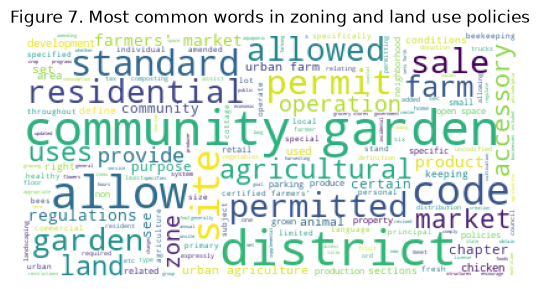

In [19]:
word_cloud = WordCloud(background_color = "white", stopwords = stop_zoning).generate(text_zoning)

plt.imshow(word_cloud)
plt.axis("off")
plt.title("Figure 7. Most common words in zoning and land use policies")
plt.show()

50 policies (8.3%) mention zoning or land use. Their summaries are mostly about community and urban gardens. "Community" shows up 50 times and "gardens" 45 times. Words like "districts", "permitted", "allowed" and "residential" suggest that many of these policies say where gardens can be placed. "Sales", "permit" and "agricultural" suggest a smaller group about selling produce and getting permits.


# <span style="color:darkblue"> VIII. Example Policies </span>

<font size = "3">

Table 8 shows examples of policies that mention breastfeeding, child care and/or child nutrition programs. Since these topics had the fewest policies, I wanted to offer a table that shares more about them.


In [21]:
list_cats = ["breastfeeding_lactation", "child_care", "child_nutrition_programs"]

for cat in list_cats:
    part = food_policy_actions[food_policy_actions[cat]].head(3)[["jurisdiction", "state", "policy_category", "summary"]].copy()
    part["Topic"] = LABELS[cat]
    list_frames.append(part)

table_examples = pd.concat(list_frames)
table_examples = table_examples.reset_index(drop = True)
table_examples = table_examples.rename(columns = {"jurisdiction": "Jurisdiction", "state": "State",
                                                  "policy_category": "Food System Category", "summary": "Summary"})
table_examples = table_examples[["Topic", "Jurisdiction", "State", "Food System Category", "Summary"]]

# Use the same renamed categories as Table 3 (only in this table, not in the data)
for i in range(len(list_old)):
    table_examples["Food System Category"] = table_examples["Food System Category"].str.replace(list_old[i], list_new[i])
table_examples.loc[table_examples["Food System Category"].notnull() == False, "Food System Category"] = "Not listed"

(make_pretty(table_examples, "Table 8. Example policies on breastfeeding, child care, and child nutrition programs", {},
             ["Topic", "Jurisdiction", "State", "Food System Category", "Summary"], [])
 .set_properties(subset = ["Summary"], **{"min-width": "400px"}))


Topic,Jurisdiction,State,Food System Category,Summary
Breastfeeding and Lactation,Alachua,Florida,Food Access,"Establishes that city employees must be allowed unpaid work breaks for expressing breast milk for up to one year after the child's birth, with other accommodations, including use of private office space for milk extraction."
Breastfeeding and Lactation,Boise,Idaho,Food Access,"This section sets various ""Healthy Initiative"" requirements for childcare facilities, including for nutrition menus, infant feeding standards and training; as well as requirements for physical activity and screen time limits. The law requires that the city monitor and disclose to the public each childcare facility's compliance with the requirements, but does not require compliance for childcare licensing. Subject to some exemptions, meals and snacks served must satisfy the USDA's Child and Adult Care Food Program (CACFP) meal patterns for infants and children, and childcare facilities must maintain records of the same. Childcare facilities are also required to provide a private, designated location, other than a restroom, for breastfeeding, which must be maintained in a sanitary condition, with access to an electrical outlet, chair and near running water."
Breastfeeding and Lactation,Buncombe County,North Carolina,Food Access,"This section of the City's Personnel Ordinance and the accompanying appendix set forth the city policy regarding break time for nursing mothers who wish to express breastmilk during the first year after a baby is born. It also provides for refrigerated storage of expressed milk. The language expressly states that ""these provisions will meet the requirements of the Fair Labor Standards Act as it relates to breaks for nursing mothers."""
Child Care,Anchorage,Alaska,Food Access,Provides nutrition standards for regulated child care facilities; adopts state standards by reference but also encourages avoidance of sugary snacks and drinks unless the drinks contain real fruit or vegetable juice.
Child Care,Boise,Idaho,Food Access,"This section sets various ""Healthy Initiative"" requirements for childcare facilities, including for nutrition menus, infant feeding standards and training; as well as requirements for physical activity and screen time limits. The law requires that the city monitor and disclose to the public each childcare facility's compliance with the requirements, but does not require compliance for childcare licensing. Subject to some exemptions, meals and snacks served must satisfy the USDA's Child and Adult Care Food Program (CACFP) meal patterns for infants and children, and childcare facilities must maintain records of the same. Childcare facilities are also required to provide a private, designated location, other than a restroom, for breastfeeding, which must be maintained in a sanitary condition, with access to an electrical outlet, chair and near running water."
Child Care,Broward County,Florida,Food Distribution; Food Access,Establishes food service requirements for child care facilities. The requirements include compliance with the Child and Adult Care Food Program (CACFP) rules and regulations regardless of whether the provider receives reimbursement from the program; service of low-fat or non-fat milk; requirements for food brought from home; menu planning; snacks; and food safety and handling. Also requires child care facilities to provide a nutritious meal if children don't receive breakfast or lunch at home.
Child Nutrition Programs,Boise,Idaho,Food Access,"This section sets various ""Healthy Initiative"" requirements for childcare facilities, including for nutrition menus, infant feeding standards and training; as well as requirements for physical activity and screen time limits. The law requires that the city monitor and disclose to the public each childcare facility's compliance with the requirements, but does not require compliance for childcare licensing. Subject to some exemptions, meals and 

# <span style="color:darkblue"> IX. Conclusions and Limitations </span>

<font size = "3">

Food policies in this database are mostly local, a few states have most of them, and they focus on food access and food production. Children and schools come up in some policies, but specific topics like breastfeeding, child care and child nutrition programs are uncommon.

There are some limits to keep in mind. About 29% of the policies (173) have no food system category, so the category percentages only describe what the website labeled. I also found topics by searching the short summaries for words, so I may have missed some policies and counted others by mistake. For example, "lead" can mean the metal or the verb, and "caps" can mean many things.

The database itself shapes the results too. It only includes enforceable local laws about healthy food access, so the focus on food access and the large share of city and county policies partly come from how it was built. It leaves out school boards, general food service rules, permit laws for farmers markets and vendors, breastfeeding laws that only mention paid leave, and zoning tables or very long zoning codes. Because of this, the counts for schools, breastfeeding, child care and zoning are probably lower than what exists in real life. The numbers describe the policies in this database, not every food policy in the United States.